In [15]:
import os
import glob
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [7]:
TRAIN_PATH = "../../datasets_challenge/train"
VAL_FILE = "train_part_006.csv"
# === Load all files ===
csv_files = sorted(glob.glob(os.path.join(TRAIN_PATH, "*.csv")))
print(f"Found {len(csv_files)} files.")

Found 22 files.


In [8]:
stats_list = []
for f in csv_files:
    df = pd.read_csv(f)
    stats = {
        "file": os.path.basename(f),
        "n_samples": len(df),
        "sideSlip_mean": df["sideSlip"].mean(),
        "sideSlip_std": df["sideSlip"].std(),
        "sideSlip_max": df["sideSlip"].max(),
        "sideSlip_min": df["sideSlip"].min(),
        "vx_mean": df["vxCG"].mean(),
        "vx_std": df["vxCG"].std(),
    }
    stats_list.append(stats)

stats_df = pd.DataFrame(stats_list)
display(stats_df.sort_values("sideSlip_std", ascending=False))

,file,n_samples,sideSlip_mean,sideSlip_std,sideSlip_max,sideSlip_min,vx_mean,vx_std
9,train_part_010.csv,11364,-1.385059,14.151366,6.42,-179.71,24.858038,15.998876
5,train_part_006.csv,24528,0.532942,10.015262,177.17,-16.54,23.257360,14.940607
11,train_part_012.csv,7292,0.264897,7.995836,179.99,-179.99,1.274550,3.429033
7,train_part_008.csv,26351,-0.062133,2.844288,12.26,-179.78,23.861680,14.622057
16,train_part_017.csv,1020,1.427931,2.080652,8.75,-0.67,4.431598,5.058159
4,train_part_005.csv,6480,0.143773,2.068540,14.61,-8.53,0.996279,1.649852
8,train_part_009.csv,33676,-0.058365,2.063228,9.61,-124.98,5.411939,11.405010
3,train_part_004.csv,10249,-0.183348,1.583693,7.83,-16.25,0.742280,1.718436
10,train_part_011.csv,33732,-0.058741,1.192474,10.62,-12.13,13.343190,16.415070
19,train_part_020.csv,9801,0.131867,1.155477,5.52,-11.05,14.152194,16.499495


In [9]:

# === Compare validation file to others ===
val_stats = stats_df[stats_df["file"] == VAL_FILE]
print("\nValidation file stats:")
display(val_stats)


Validation file stats:


,file,n_samples,sideSlip_mean,sideSlip_std,sideSlip_max,sideSlip_min,vx_mean,vx_std
5,train_part_006.csv,24528,0.532942,10.015262,177.17,-16.54,23.25736,14.940607


In [ ]:
# Thresholds for band definitions
MANY_MAX = 1.0      # |sideslip| ≤ 1° → many-shot
MEDIUM_MAX = 5.0    # 1° < |sideslip| ≤ 5° → medium-shot


for f in csv_files:
    df = pd.read_csv(f)
    abs_slip = df["sideSlip"].abs()
    total = len(abs_slip)
    
    # Count samples per region
    many = (abs_slip <= MANY_MAX).sum()
    medium = ((abs_slip > MANY_MAX) & (abs_slip <= MEDIUM_MAX)).sum()
    few = (abs_slip > MEDIUM_MAX).sum()
    
    stats = {
        "file": os.path.basename(f),
        "n_samples": total,
        "many": many,
        "medium": medium,
        "few": few,
        "many_%": 100 * many / total,
        "medium_%": 100 * medium / total,
        "few_%": 100 * few / total,
        "mean_sideslip": df["sideSlip"].mean(),
        "std_sideslip": df["sideSlip"].std(),
        "max_sideslip": df["sideSlip"].max(),
        "min_sideslip": df["sideSlip"].min(),
    }
    stats_list.append(stats)

stats_df = pd.DataFrame(stats_list)

In [12]:
# === Display table ===
print("\n📊 Sideslip Region Distribution per File:")
display(stats_df.sort_values("few_%", ascending=False))


📊 Sideslip Region Distribution per File:


,file,n_samples,sideSlip_mean,sideSlip_std,sideSlip_max,sideSlip_min,vx_mean,vx_std,many,medium,few,many_%,medium_%,few_%,mean_sideslip,std_sideslip,max_sideslip,min_sideslip
38,train_part_017.csv,1020,NaN,NaN,NaN,NaN,NaN,NaN,641.0,279.0,100.0,62.843137,27.352941,9.803922,1.427931,2.080652,8.75,-0.67
26,train_part_005.csv,6480,NaN,NaN,NaN,NaN,NaN,NaN,5606.0,552.0,322.0,86.512346,8.518519,4.969136,0.143773,2.068540,14.61,-8.53
25,train_part_004.csv,10249,NaN,NaN,NaN,NaN,NaN,NaN,9348.0,565.0,336.0,91.208898,5.512733,3.278369,-0.183348,1.583693,7.83,-16.25
31,train_part_010.csv,11364,NaN,NaN,NaN,NaN,NaN,NaN,7301.0,3730.0,333.0,64.246744,32.822950,2.930306,-1.385059,14.151366,6.42,-179.71
27,train_part_006.csv,24528,NaN,NaN,NaN,NaN,NaN,NaN,17723.0,6156.0,649.0,72.256197,25.097847,2.645956,0.532942,10.015262,177.17,-16.54
33,train_part_012.csv,7292,NaN,NaN,NaN,NaN,NaN,NaN,6743.0,409.0,140.0,92.471201,5.608886,1.919912,0.264897,7.995836,179.99,-179.99
28,train_part_007.csv,10849,NaN,NaN,NaN,NaN,NaN,NaN,10144.0,560.0,145.0,93.501705,5.161766,1.336529,-0.063347,1.022159,9.97,-8.13
41,train_part_020.csv,9801,NaN,NaN,NaN,NaN,NaN,NaN,8313.0,1361.0,127.0,84.817876,13.886338,1.295786,0.131867,1.155477,5.52,-11.05
24,train_part_003.csv,32215,NaN,NaN,NaN,NaN,NaN,NaN,29545.0,2303.0,367.0,91.711935,7.148844,1.139221,-0.019741,0.994921,13.01,-9.83
32,train_part_011.csv,33732,NaN,NaN,NaN,NaN,NaN,NaN,29003.0,4356.0,373.0,85.980671,12.913554,1.105775,-0.058741,1.192474,10.62,-12.13


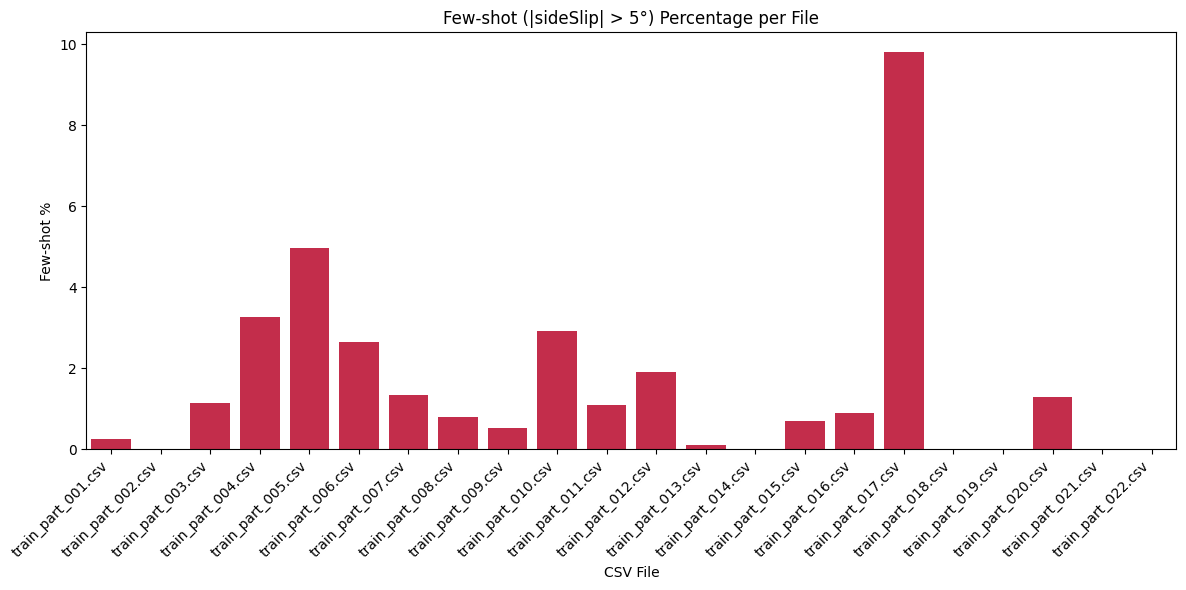

In [13]:
# === Plot percentage of few-shot samples per file ===
plt.figure(figsize=(12,6))
sns.barplot(data=stats_df, x="file", y="few_%", color="crimson")
plt.xticks(rotation=45, ha="right")
plt.title("Few-shot (|sideSlip| > 5°) Percentage per File")
plt.ylabel("Few-shot %")
plt.xlabel("CSV File")
plt.tight_layout()
plt.show()

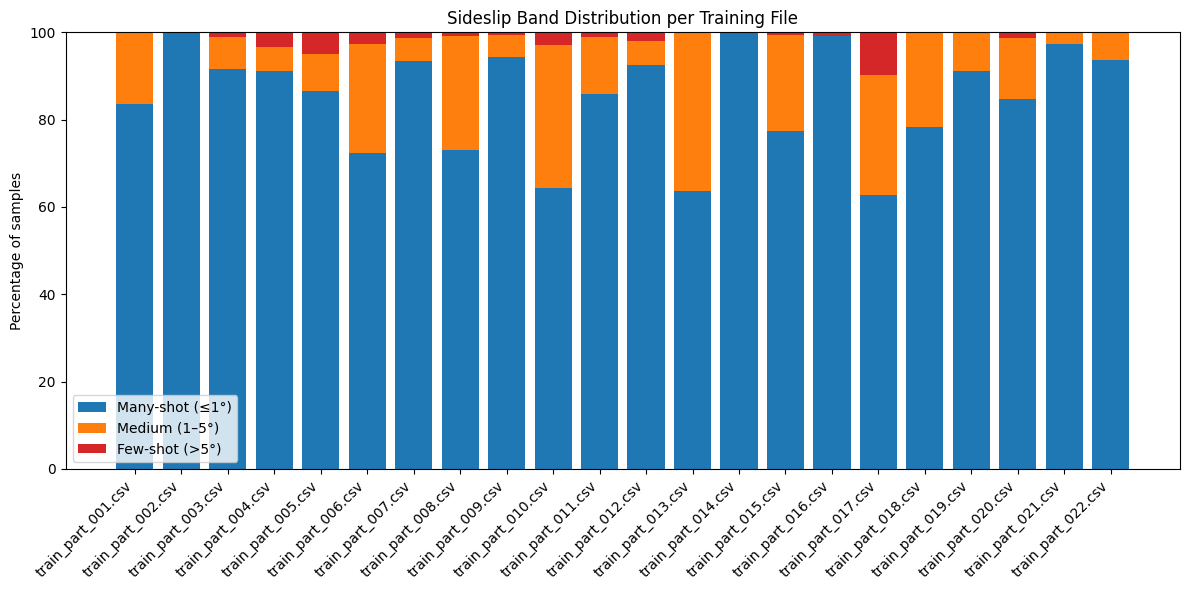

In [14]:

# === Plot stacked bar for all three regions ===
plt.figure(figsize=(12,6))
plt.bar(stats_df["file"], stats_df["many_%"], label="Many-shot (≤1°)", color="#1f77b4")
plt.bar(stats_df["file"], stats_df["medium_%"], bottom=stats_df["many_%"], label="Medium (1–5°)", color="#ff7f0e")
plt.bar(stats_df["file"], stats_df["few_%"], bottom=stats_df["many_%"] + stats_df["medium_%"], label="Few-shot (>5°)", color="#d62728")
plt.xticks(rotation=45, ha="right")
plt.ylabel("Percentage of samples")
plt.title("Sideslip Band Distribution per Training File")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

TRAIN_PATH = CONFIG['TRAIN_PATH']

# Define sideslip thresholds
MANY_MAX = 2.4
MED_MAX = 5.0

def classify_band(value):
    if abs(value) <= MANY_MAX:
        return "many"
    elif abs(value) <= MED_MAX:
        return "medium"
    else:
        return "few"

# Analyze each file
stats = []
for fname in sorted(os.listdir(TRAIN_PATH)):
    if not fname.endswith(".csv"):
        continue
    fpath = os.path.join(TRAIN_PATH, fname)
    df = pd.read_csv(fpath)
    
    if 'sideSlip' not in df.columns:
        continue  # skip corrupted files
    
    bands = df['sideSlip'].apply(classify_band)
    counts = bands.value_counts(normalize=True)
    
    many = counts.get("many", 0)
    med = counts.get("medium", 0)
    few = counts.get("few", 0)
    
    stats.append({
        "file": fname,
        "n_samples": len(df),
        "many_pct": many * 100,
        "med_pct": med * 100,
        "few_pct": few * 100
    })

dist_df = pd.DataFrame(stats)
dist_df = dist_df.sort_values("few_pct", ascending=False).reset_index(drop=True)

# Show summary table
print(dist_df.head(10))
print(f"\n📊 Total files analyzed: {len(dist_df)}")

# Plot the few/medium/many ratios
plt.figure(figsize=(12, 6))
plt.bar(dist_df['file'], dist_df['few_pct'], label="Few-shot", color='red')
plt.bar(dist_df['file'], dist_df['med_pct'], bottom=dist_df['few_pct'], label="Medium-shot", color='orange')
plt.bar(dist_df['file'], dist_df['many_pct'], bottom=dist_df['few_pct']+dist_df['med_pct'], label="Many-shot", color='blue')
plt.xticks(rotation=90)
plt.ylabel("Percentage (%)")
plt.title("Distribution of Many / Medium / Few per train_part_*.csv")
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()
